
## Evaluating the performance of a hybrid power plant with P2X using HyDesign

In this notebook we will evaluate a hybrid power plant design in a specific location.

A hybrid power plant design consists on selecting the following parameters:

**Wind Plant design:**

1. Number of wind turbines in the wind plant [-] (`Nwt`)
2. Wind power installation density [MW/km2] (`wind_MW_per_km2`): This parameter controls how closely spaced are the turbines, which in turns affect how much wake losses are present.

**PV Plant design:**

3. Solar plant power capacity [MW] (`solar_MW`)

**Battery Storage design:**

4. Battery power [MW] (`b_P`)
5. Battery energy capacity in hours [MWh] (`b_E_h `): Battery storage capacity in hours of full battery power (`b_E = b_E_h * b_P `). 
6. Cost of battery power fluctuations in peak price ratio [-] (`cost_of_batt_degr`): This parameter controls how much penalty is given to do ramps in battery power in the HPP operation.

**Electrolyzer design:**

7. Electrolyzer capacity [MW] (`ptg_MW`)
8. H2 storage capacity [kg] (`HSS_kg`)

##
**Imports**

Install hydesign if needed.
Import basic libraries. 
Import HPP model assembly class.
Import the examples file path.

In [1]:
# Install hydesign if needed
import importlib
if not importlib.util.find_spec("hydesign"):
    !pip install git+https://gitlab.windenergy.dtu.dk/TOPFARM/hydesign.git   

In [2]:
import os
import time
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hydesign.assembly.hpp_assembly_P2X_pyomo import hpp_model_P2X_pyomo as hpp_model
from hydesign.examples import examples_filepath

##
**Specifying the site**

Hydesign, provides example data from several sites in India and Europe. 

The site coordinates (longitude, latitude, and altitude) are given in `examples_sites.csv`.

In [3]:
examples_sites = pd.read_csv(f'{examples_filepath}examples_sites.csv', index_col=0, sep=';')
examples_sites

,case,name,longitude,latitude,altitude,input_ts_fn,sim_pars_fn,price_fn,price_col,H2_demand_col,input_HA_ts_fn,price_up_ts,price_dwn_ts
0,India,Indian_site_good_wind,77.500226,8.334294,679.803454,India/GWA2/input_ts_Indian_site_good_wind.csv,India/hpp_pars.yml,India/Indian_elec_price_t.csv,Price,India/H2_demand.csv,NaN,NaN,NaN
1,India,Indian_site_good_solar,68.542204,23.542099,29.883557,India/GWA2/input_ts_Indian_site_good_solar.csv,India/hpp_pars.yml,India/Indian_elec_price_t.csv,Price,India/H2_demand.csv,NaN,NaN,NaN
2,India,Indian_site_bad_solar_bad_wind,77.916878,17.292316,627.424643,India/GWA2/input_ts_Indian_site_bad_solar_bad_...,India/hpp_pars.yml,India/Indian_elec_price_t.csv,Price,India/H2_demand.csv,NaN,NaN,NaN
3,Europe,France_good_solar,4.229736,44.422011,204.000000,Europe/GWA2/input_ts_France_good_solar.csv,Europe/hpp_pars.yml,Europe/2030-EL_PRICE.csv,FR_R,Europe/H2_demand.csv,NaN,NaN,NaN
4,Europe,France_good_wind,-0.864258,48.744116,302.000000,Europe/GWA2/input_ts_France_good_wind.csv,Europe/hpp_pars.yml,Europe/2030-EL_PRICE.csv,FR_R,Europe/H2_demand.csv,NaN,NaN,NaN
5,Europe,France_bad_solar_n_wind,2.167969,47.428087,140.000000,Europe/GWA2/input_ts_France_bad_solar_n_wind.csv,Europe/hpp_pars.yml,Europe/2030-EL_PRICE.csv,FR_R,Europe/H2_demand.csv,NaN,NaN,NaN
6,Europe,Germany_bad_solar_n_wind,10.766602,49.310798,442.000000,Europe/GWA2/input_ts_Germany_bad_solar_n_wind.csv,Europe/hpp_pars.yml,Europe/2030-EL_PRICE.csv,DE_ME,Europe/H2_demand.csv,NaN,NaN,NaN
7,Europe,Germany_good_wind,7.873535,53.287111,5.000000,Europe/GWA2/input_ts_Germany_good_wind.csv,Europe/hpp_pars.yml,Europe/2030-EL_PRICE.csv,DE_NW,Europe/H2_demand.csv,NaN,NaN,NaN
8,Europe,Denmark_good_solar,11.813965,55.397760,42.000000,Europe/GWA2/input_ts_Denmark_good_solar.csv,Europe/hpp_pars.yml,Europe/2030-EL_PRICE.csv,DK_E,Europe/H2_demand.csv,NaN,NaN,NaN
9,Europe,Denmark_good_wind,8.594398,56.227322,85.000000,Europe/GWA2/input_ts_Denmark_good_wind.csv,Europe/hpp_pars.yml,Europe/2030-EL_PRICE.csv,DK_W,Europe/H2_demand.csv,NaN,NaN,NaN


##
**Select a site to run**

In [4]:
name = 'Denmark_good_wind'

ex_site = examples_sites.loc[examples_sites.name == name]

longitude = ex_site['longitude'].values[0]
latitude = ex_site['latitude'].values[0]
altitude = ex_site['altitude'].values[0]

In [5]:
# Weather data and Price data
input_ts_fn = examples_filepath+ex_site['input_ts_fn'].values[0]

input_ts = pd.read_csv(input_ts_fn, index_col=0, parse_dates=True)

required_cols = [col for col in input_ts.columns if 'WD' not in col]
input_ts = input_ts.loc[:,required_cols]
input_ts

,WS_1,WS_50,WS_100,WS_150,WS_200,temp_air_1,ghi,dni,dhi,Price,Unnamed: 16
2012-01-01 00:00:00,2.803428,6.289076,8.109687,8.777118,10.335076,276.767325,0.035121,0.0,0.035121,35.171,NaN
2012-01-01 01:00:00,2.791624,6.275261,8.093319,8.910806,10.407985,277.374423,0.017560,0.0,0.017560,35.171,NaN
2012-01-01 02:00:00,3.036807,6.656427,8.547709,9.467695,10.864995,278.015879,0.000000,0.0,0.000000,35.171,NaN
2012-01-01 03:00:00,3.405581,7.233561,9.237670,10.435093,11.793017,278.655888,0.000000,0.0,0.000000,35.171,NaN
2012-01-01 04:00:00,3.649363,7.542440,9.584774,10.864283,12.081760,279.290819,0.000000,0.0,0.000000,35.171,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2012-12-30 19:00:00,3.263756,7.267221,9.358232,10.267748,11.455513,277.214861,0.000000,0.0,0.000000,35.446,NaN
2012-12-30 20:00:00,3.368223,7.417605,9.533621,10.482431,11.694345,276.913527,0.000000,0.0,0.000000,33.565,NaN
2012-12-30 21:00:00,3.392954,7.546295,9.715589,10.655855,11.978293,277.356365,0.000000,0.0,0.000000,32.709,NaN
2012-12-30 22:00:00,3.898207,8.486008,10.884241,11.965626,13.407147,278.369005,0.000000,0.0,0.000000,31.392,NaN


In [6]:
# Hydrogen demand data, when H2 offtake is infinite -> make H2_demand values very high (1e6) in H2_demand.csv file and penalty_H2 as '0' in hpp_pars.yml file
H2_demand_fn = examples_filepath+ex_site['H2_demand_col'].values[0]

H2_demand_ts = pd.read_csv(H2_demand_fn, index_col=0, parse_dates=True)
H2_demand_ts

,H2_demand
2012-01-01 00:00:00,10000
2012-01-01 01:00:00,10000
2012-01-01 02:00:00,10000
2012-01-01 03:00:00,10000
2012-01-01 04:00:00,10000
...,...
2012-12-31 19:00:00,10000
2012-12-31 20:00:00,10000
2012-12-31 21:00:00,10000
2012-12-31 22:00:00,10000


In [7]:
# Input data of technology's cost
sim_pars_fn = examples_filepath+ex_site['sim_pars_fn'].values[0]

with open(sim_pars_fn) as file:
    sim_pars = yaml.load(file, Loader=yaml.FullLoader)

print(sim_pars_fn)    
sim_pars

C:/Users/s223344/hydesign/hydesign/examples/Europe/hpp_pars.yml


{'G_MW': 300,
 'year': '2012',
 'N_life': 25,
 'wind_turbine_cost': 640000,
 'wind_civil_works_cost': 260000,
 'wind_fixed_onm_cost': 12600,
 'wind_variable_onm_cost': 1.35,
 'd_ref': 145,
 'hh_ref': 100,
 'p_rated_ref': 5.0,
 'wpp_efficiency': 1,
 'wind_deg_yr': [0, 25],
 'wind_deg': [0, 0.25],
 'share_WT_deg_types': 0.5,
 'solar_PV_cost': 110000,
 'solar_hardware_installation_cost': 100000,
 'solar_inverter_cost': 20000,
 'solar_fixed_onm_cost': 4500,
 'land_use_per_solar_MW': 0.01226,
 'tracking': 'No',
 'pv_deg_yr': [0, 1, 25],
 'pv_deg': [0.03, 0.03, 0.28],
 'latitude': None,
 'longitude': None,
 'altitude': None,
 'battery_energy_cost': 62000,
 'battery_power_cost': 16000,
 'battery_BOP_installation_commissioning_cost': 80000,
 'battery_control_system_cost': 2250,
 'battery_energy_onm_cost': 0,
 'battery_depth_of_discharge': 0.9,
 'battery_charge_efficiency': 0.985,
 'battery_price_reduction_per_year': 0.1,
 'min_LoH': 0.7,
 'n_full_power_hours_expected_per_day_at_peak_price': 0,

## 
**Initializing the HPP model**

Initialize the HPP model (hpp_model class) with the coordinates and the necessary input files.

In [8]:
hpp = hpp_model(
        latitude=latitude,
        longitude=longitude,
        altitude=altitude,
        num_batteries = 3,
        work_dir = './',
        sim_pars_fn = sim_pars_fn,
        input_ts_fn = input_ts_fn,
        H2_demand_fn = H2_demand_fn, 
)


Fixed parameters on the site
-------------------------------
longitude = 8.594398
latitude = 56.227322
altitude = 85.0


##
### Evaluating the HPP model

In [9]:
start = time.time()

clearance = 10
sp = 360
p_rated = 4        
Nwt = 90
wind_MW_per_km2 = 5
solar_MW = 80
surface_tilt = 50
surface_azimuth = 210
DC_AC_ratio = 1.5
b_P = 50
b_E_h  = 3
cost_of_batt_degr = 10
ptg_MW = 130
HSS_kg = 0

x = [clearance, sp, p_rated, Nwt, wind_MW_per_km2, solar_MW, \
surface_tilt, surface_azimuth, DC_AC_ratio, b_P, b_E_h , cost_of_batt_degr, ptg_MW, HSS_kg]

outs = hpp.evaluate(*x)

hpp.print_design(x, outs)

end = time.time()
print(f'exec. time [min]:', (end - start)/60 )

wind hasna? False min,max: 66.14903042980698 203.8248227574837
solar hasna? False min,max: 0.0 58.260212110895694
price hasna? False min,max: 32.158 50.707
E_batt hasna? False min,max: 150.0 150.0
H2_storage hasna? False min,max: 0.0 0.0
**WARNING: Piecewise component 'h2_storage_eff_constraint[(0,)]' has detected slopes of consecutive piecewise segments to be within 1e-08 of one another. Refer to the Piecewise help documentation for information on how to disable this warning.
**WARNING: Piecewise component 'h2_storage_eff_constraint[(1,)]' has detected slopes of consecutive piecewise segments to be within 1e-08 of one another. Refer to the Piecewise help documentation for information on how to disable this warning.
**WARNING: Piecewise component 'h2_storage_eff_constraint[(2,)]' has detected slopes of consecutive piecewise segments to be within 1e-08 of one another. Refer to the Piecewise help documentation for information on how to disable this warning.
**WARNING: Piecewise component

RuntimeError: 'ems' <class ems_P2X_pyomo>: Error calling compute(), Attempting to use an unavailable solver.

The SolverFactory was unable to create the solver "glop"
and returned an UnknownSolver object.  This error is raised at the point
where the UnknownSolver object was used as if it were valid (by calling
method "solve").

The original solver was created with the following parameters:
	executable: glop
	type: glop
	_args: ()
	options: {}

##
### Plot the HPP operation

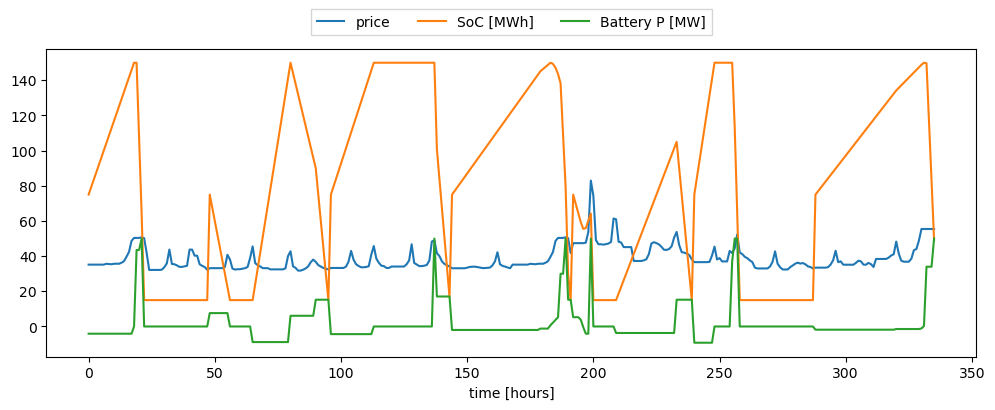

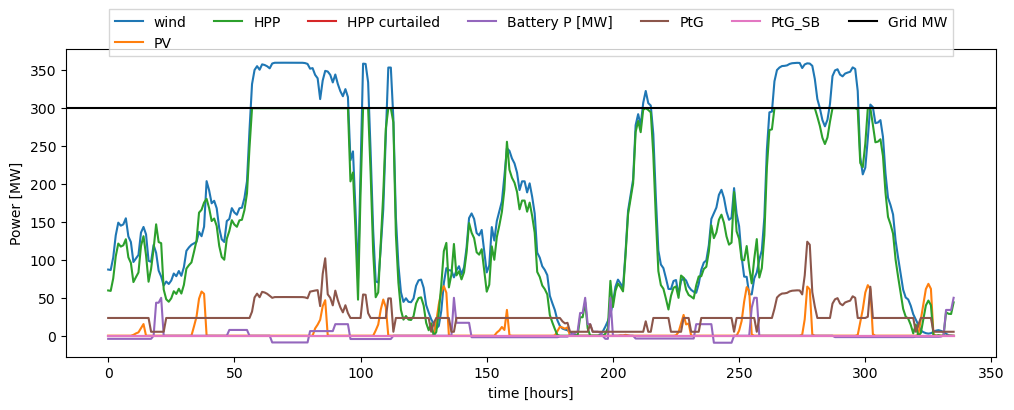

In [ ]:
b_E_SOC_t = hpp.prob.get_val('ems.b_E_SOC_t')
b_t = hpp.prob.get_val('ems.b_t')
price_t = hpp.prob.get_val('ems.price_t')

wind_t = hpp.prob.get_val('ems.wind_t')
solar_t = hpp.prob.get_val('ems.solar_t')
hpp_t = hpp.prob.get_val('ems.hpp_t')
hpp_curt_t = hpp.prob.get_val('ems.hpp_curt_t')
P_ptg_t = hpp.prob.get_val('ems.P_ptg_t')
P_ptg_SB_t = hpp.prob.get_val('ems.P_ptg_SB_t')
grid_MW = hpp.prob.get_val('ems.G_MW')

m_H2_t = hpp.prob.get_val('ems.m_H2_t')
m_H2_demand_t = hpp.prob.get_val('ems.m_H2_demand_t_ext')
m_H2_offtake_t = hpp.prob.get_val('ems.m_H2_offtake_t')
LoS_H2_t = hpp.prob.get_val('ems.LoS_H2_t')

n_days_plot = 14
plt.figure(figsize=[12,4])
plt.plot(price_t[:24*n_days_plot], label='price')
plt.plot(b_E_SOC_t[:24*n_days_plot], label='SoC [MWh]')
plt.plot(b_t[:24*n_days_plot], label='Battery P [MW]')
plt.xlabel('time [hours]')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15),
           ncol=3, fancybox=0, shadow=0)

plt.figure(figsize=[12,4])
plt.plot(wind_t[:24*n_days_plot], label='wind')
plt.plot(solar_t[:24*n_days_plot], label='PV')
plt.plot(hpp_t[:24*n_days_plot], label='HPP')
plt.plot(hpp_curt_t[:24*n_days_plot], label='HPP curtailed')
plt.plot(b_t[:24*n_days_plot], label='Battery P [MW]')
plt.plot(P_ptg_t[:24*n_days_plot], label='PtG')
plt.plot(P_ptg_SB_t[:24*n_days_plot], label='PtG_SB')
plt.axhline(grid_MW, label='Grid MW', color='k')
plt.xlabel('time [hours]')
plt.ylabel('Power [MW]')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15),
           ncol=7, fancybox=0, shadow=0)


In [ ]:
results = {'Wind': wind_t, 'PV': solar_t, 'HPP': hpp_t[:8760], 'Curtailment': hpp_curt_t[:8760],\
                    'Battery power': b_t[:8760], 'Energy Level': b_E_SOC_t[:8760], 'Prices': price_t, 'PtG': P_ptg_t[:8760], 'Mass H2': m_H2_t[:8760], 'PtG_SB': P_ptg_SB_t[:8760],}
df = pd.DataFrame(results)
df.to_csv('EMS_out_9_P2X.csv')

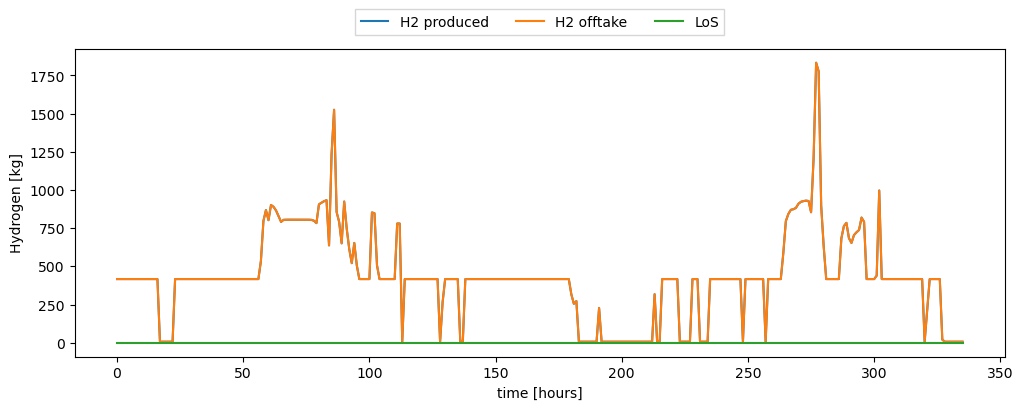

In [ ]:

plt.figure(figsize=[12,4])
plt.plot(m_H2_t[:24*n_days_plot], label='H2 produced')
plt.plot(m_H2_offtake_t[:24*n_days_plot], label='H2 offtake')
#plt.plot(m_H2_demand_t[:24*n_days_plot], label='H2 demand')
plt.plot(LoS_H2_t[:24*n_days_plot], label='LoS')
plt.xlabel('time [hours]')
plt.ylabel('Hydrogen [kg]')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15),
           ncol=5, fancybox=0, shadow=0)